# Project 3 (Due November 6): Clustering and Anomaly Detection


This project studies two different kinds of irregularities in financial data: **isolated recording errors** and a **contiguous interval of unusual joint statistical behavior**. You will use DBSCAN for the former and window-based covariance representations with PCA, K-means, and hierarchical clustering for the latter.

Use only `polluteddata.csv`. You may use NumPy, pandas, SciPy, Matplotlib, and scikit-learn. Fix random seeds where appropriate and state your main modeling choices.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

SEED = 4500


## Data

The file contains **1,709 half-hour observations of one asset**, with no header. Using zero-based column numbers, column 0 is the half-hour index $t$, and column $k+1$ contains

$$
x_{t,k}=p(t,k)-p(t,0),\qquad k=0,\ldots,29,
$$

where $p(t,k)$ is the recorded price at minute $k$ within half-hour $t$. These are price differences, **not** percentage returns. Each row therefore includes the half-hour index and 30 intraperiod measurements (the minute-0 price change is zero).

The data contain **exactly six isolated recording errors**, at unknown observations and minutes. Separately, during an unknown **contiguous interval $[t_1,t_2]$**, the data exhibit a significant change in their **joint statistical behavior**, particularly covariance structure. Your goals are to identify the six isolated errors and estimate the anomalous interval.



In [12]:
data = pd.read_csv('polluteddata.csv', header=None)
print('Data shape:', data.shape)
print(data.head(3))


Data shape: (1709, 31)
    0    1     2     3      4     5      6      7      8      9   ...     21  \
0  0.0  0.0 -3.00 -8.26 -10.55 -8.56 -18.08 -12.67 -14.29 -16.08  ... -27.58   
1  1.0  0.0  0.12 -0.41  -2.56  0.15  -1.65  -5.14  -5.09  -8.06  ...  -6.65   
2  2.0  0.0 -2.80 -3.46  -5.80 -3.86  -2.60  -5.30  -4.81  -3.30  ... -12.74   

      22     23     24     25     26     27     28     29     30  
0 -31.51 -27.53 -25.24 -25.32 -24.44 -28.04 -30.94 -29.57 -27.56  
1  -5.43  -6.13  -3.42  -4.48  -4.85  -4.47  -4.68  -2.10  -0.28  
2 -13.02 -15.99 -14.15 -14.92 -16.80 -16.88 -19.53 -25.30 -19.60  

[3 rows x 31 columns]


# Task 1: Data exploration and preprocessing

Inspect the data, check its basic structure and quality, and provide a simple exploratory visualization. Prepare suitable feature representations for the subsequent tasks.

In [13]:
# Task 1: your data exploration and preprocessing


print("Shape:", data.shape)
print("\nData types:")
print(data.dtypes.value_counts())


print("\nMissing values:", data.isna().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Infinite values:", np.isinf(data.to_numpy()).sum())

print("\nSummary statistics:")
display(data.iloc[:, 1:].describe())

Shape: (1709, 31)

Data types:
float64    31
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0
Infinite values: 0

Summary statistics:


,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
count,1709.0,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,...,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000
mean,0.0,0.094744,0.006594,0.066914,0.294528,0.224361,0.313219,-0.004143,0.169033,0.091920,...,-0.273401,0.209558,0.186624,0.278519,0.278602,-0.131089,0.171991,-0.135022,-0.105291,0.291442
std,0.0,3.247338,6.197354,6.034463,5.546020,6.385154,6.846385,10.741715,7.988759,8.606869,...,17.102589,10.611540,10.812969,11.127263,11.527265,14.472260,12.298652,14.325939,15.023754,13.195456
min,0.0,-15.650000,-56.960000,-66.380000,-38.380000,-46.020000,-46.740000,-64.360000,-47.880000,-51.720000,...,-96.827911,-68.190000,-72.410000,-78.670000,-70.880000,-75.600000,-74.070000,-71.777607,-78.234077,-64.820000
25%,0.0,-1.100000,-1.779856,-2.260000,-2.230000,-2.750000,-2.990000,-3.540000,-3.740000,-4.160000,...,-6.090000,-5.480000,-5.420000,-5.420364,-5.720000,-6.610000,-5.980000,-6.950000,-7.220000,-6.600000
50%,0.0,-0.010000,0.070000,0.040000,0.060000,0.080000,0.050000,0.100000,0.040000,0.060000,...,-0.200000,-0.130000,-0.340000,-0.080000,-0.140000,-0.230000,-0.230000,-0.490000,-0.310000,-0.070000
75%,0.0,1.188527,1.860000,2.290000,2.392062,2.890000,3.200000,3.520000,3.460000,3.520000,...,5.880000,5.300000,5.270000,5.370000,5.530000,5.770000,5.630000,5.980000,6.290000,6.540000
max,0.0,60.380000,67.930000,64.060000,68.040000,76.880000,83.300000,78.830000,84.440000,79.840000,...,87.569365,88.050000,88.300000,92.190000,96.050000,100.080000,101.070000,94.510000,98.690000,101.570000


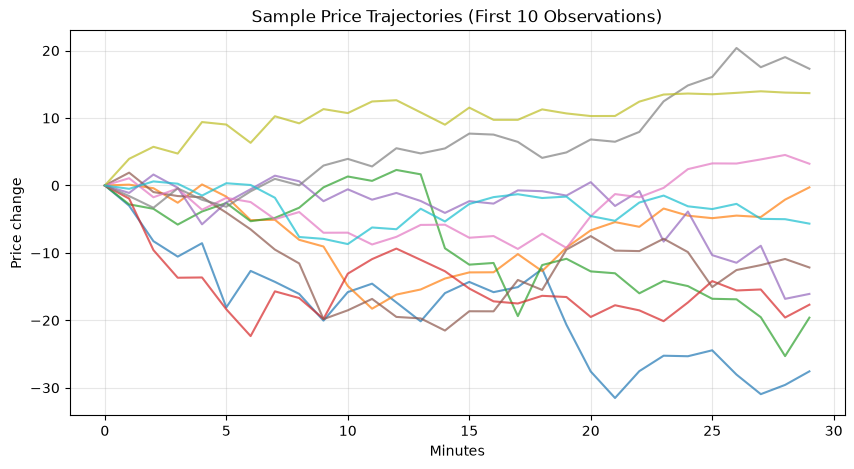

In [14]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.plot(range(30), data.iloc[i, 1:], alpha=0.7)

plt.xlabel("Minutes")
plt.ylabel("Price change")
plt.title("Sample Price Trajectories (First 10 Observations)")
plt.grid(alpha=0.3)
plt.show()


From the above graph, we can see that the sampled price trajectorie all begin at 0 at time 0 and diverge from there. The spread in behavior increases over time, and further analysis is required to understand this.

In [15]:
time_idx = data.iloc[:, 0].to_numpy()
X = data.iloc[:, 1:].to_numpy()

# minute-to-minute price changes
X_diff = np.diff(X, axis=1)

print("Original features:", X.shape)
print("Minute-to-minute changes:", X_diff.shape)

Original features: (1709, 30)
Minute-to-minute changes: (1709, 29)


In [16]:
from sklearn.preprocessing import StandardScaler

X_features = X[:, 1:]

# standardize feature representations
X_scaled = StandardScaler().fit_transform(X_features)
X_diff_scaled = StandardScaler().fit_transform(X_diff)

print("Scaled price changes:", X_scaled.shape)
print("Scaled minute-to-minute changes:", X_diff_scaled.shape)


Scaled price changes: (1709, 29)
Scaled minute-to-minute changes: (1709, 29)


The dataset has 1709 observations and 30 price measurements per observation. There are no missing or duplicate rows. In the graph, we saw that the price may fluctuate either up or down, and the spread generally increased with time over the 30 minute dataset given. For preprocessing, minute 0 was removed and time indices were separated from price measurements. We also calculated the minute by minute changes of the price so that we can see more specific changes rather than just the cumulative movement. We also created a standardized version of both feature representations (for distance-based clustering). The original dataset was retained and no observations were removed.

# Task 2: DBSCAN — isolated recording errors

Apply DBSCAN to identify the **six isolated recording errors**.

1. Choose a representation of each half-hour observation and an appropriate distance metric. Briefly justify your choices.
2. Select `eps` and `min_samples`, using a neighborhood-distance diagnostic or another systematic parameter-selection approach. You **may use the known number of recording errors (six)** to guide your selection, but should not assume that six noise labels guarantee six correct detections.
3. Report the candidate error half-hour indices, the number of DBSCAN clusters, and the noise count.
4. Examine whether your results remain reasonably stable for nearby parameter choices, and discuss possible false positives or missed errors.

Do not assume that DBSCAN noise observations must coincide with the contiguous anomalous interval.

In [17]:
# Task 2: your DBSCAN implementation and analysis

A *window* in Tasks 3–4 consists of consecutive **half-hour observations (rows)**, not consecutive minutes within a half-hour. Cluster labels are arbitrary; a cluster or noise label alone does not prove that an observation is anomalous.

# Task 3: Window-based covariance analysis, PCA, and K-means

The main objective is to identify the **contiguous interval** with unusual joint statistical behavior. Instead of clustering individual half-hours, study how the data's covariance structure evolves across **windows of consecutive half-hours**.

1. Construct an informative window-level representation of covariance behavior. Choose and briefly motivate the windowing and feature-design choices.
2. Use **PCA and K-means** to investigate patterns across windows. Select reasonable settings and interpret the resulting groups.
3. Provide visualizations that connect the window-level results back to time and indicate any unusual statistical regime.
4. Report an estimated interval $[\hat t_1,\hat t_2]$ and explain how you infer its boundaries from your results. Discuss any important uncertainty introduced by the window construction.

You have flexibility in feature construction and parameter selection; justify your design rather than following a prescribed recipe.

In [18]:
# Task 3: your window features, PCA, K-means, and interval estimate

# Task 4: Hierarchical clustering with temporal connectivity

Use a **window-level representation** from Task 3 to investigate time-series segmentation with **Ward hierarchical clustering and temporal connectivity constraints**.

1. Apply Ward clustering with a connectivity graph that links neighboring windows in chronological order. Select a reasonable number of segments.
2. Visualize the clustering labels over time and summarize the resulting contiguous segments and their boundaries.
3. Compare the segmentation and candidate change points with your K-means analysis in Task 3. Does it support a similar anomalous interval? Discuss important differences and limitations.

Remember that a segment boundary is a **candidate change point**, not automatically evidence of anomalous behavior.

In [19]:
# Task 4: your connectivity-constrained Ward clustering

# Task 5: Comparison and conclusion

Summarize the main findings from **DBSCAN, window covariance + PCA + K-means, and connectivity-constrained Ward**. Explain which approach is suited to isolated errors and which to an anomalous interval in the covariance structure.

Report your final six candidate recording-error observations and your best estimate of $[t_1,t_2]$, with brief evidence and limitations.

In [20]:
# Task 5: your comparison and final conclusions